# Advanced Statistical Analysis & Hypothesis Testing

**Dataset:** Scikit-learn Diabetes Dataset (442 observations)  
**Outcome:** Disease progression measure  
**Significance level:** \(\alpha = 0.05\)

## Project objective
This notebook demonstrates normality testing, parametric and non-parametric two-group comparisons, one-way ANOVA with Tukey HSD, and two-way ANOVA.

**Important:** This is an observational dataset. Statistical association does not establish causation. The dataset's BMI and sex features are preprocessed/standardized by scikit-learn. BMI groups are formed from tertiles for demonstration; the resulting cut points are sample-specific.

## 1. Research questions and hypotheses

1. Does the outcome distribution differ between the two encoded sex groups?
2. Does mean disease progression differ across low, medium, and high BMI groups?
3. Are BMI group, encoded sex group, or their interaction associated with the outcome?

### Hypotheses

**Two-sample t-test**
- \(H_0: \mu_1 = \mu_2\)
- \(H_1: \mu_1 \ne \mu_2\)

**Mann–Whitney U test**
- \(H_0\): the two groups have the same distribution (under the usual interpretation).
- \(H_1\): the distributions differ.

**One-way ANOVA**
- \(H_0: \mu_{low}=\mu_{medium}=\mu_{high}\)
- \(H_1\): at least one group mean differs.

**Two-way ANOVA**
- BMI group has no main effect; encoded sex group has no main effect; and there is no BMI-group-by-sex interaction.
- The alternative for each effect is that the corresponding effect is non-zero.

## 2. Install dependencies if needed

Run this in a terminal (not as Python code in a notebook cell):

```bash
python -m pip install pandas numpy scipy matplotlib seaborn statsmodels scikit-learn jupyter
```

If you already have these packages installed, continue to the next cell.

Dependencies are listed in the setup cell above. If needed, install them from the terminal before running the notebook; this notebook does not install packages during analysis.

In [1]:
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multicomp import pairwise_tukeyhsd

print("statsmodels installed successfully!")

statsmodels installed successfully!


In [2]:
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multicomp import pairwise_tukeyhsd

print("All imports are working successfully!")

All imports are working successfully!


In [3]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from sklearn.datasets import load_diabetes
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multicomp import pairwise_tukeyhsd

ALPHA = 0.05
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

## 3. Load and inspect the dataset

The Diabetes dataset is included with scikit-learn, so no separate data download is required. Its target is a quantitative measure of disease progression one year after baseline. The `bmi` and `sex` features are standardized/encoded, rather than being raw BMI values or directly labeled demographics.

In [4]:
diabetes = load_diabetes(as_frame=True)
df = diabetes.frame.copy()
df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.0381,0.0507,0.0617,0.0219,-0.0442,-0.0348,-0.0434,-0.0026,0.0199,-0.0176,151.0000
1,-0.0019,-0.0446,-0.0515,-0.0263,-0.0084,-0.0192,0.0744,-0.0395,-0.0683,-0.0922,75.0000
2,0.0853,0.0507,0.0445,-0.0057,-0.0456,-0.0342,-0.0324,-0.0026,0.0029,-0.0259,141.0000
3,-0.0891,-0.0446,-0.0116,-0.0367,0.0122,0.0250,-0.0360,0.0343,0.0227,-0.0094,206.0000
4,0.0054,-0.0446,-0.0364,0.0219,0.0039,0.0156,0.0081,-0.0026,-0.0320,-0.0466,135.0000


In [5]:
print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nMissing values:", int(df.isna().sum().sum()))
df.describe().T

Shape: (442, 11)

Columns: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6', 'target']

Missing values: 0


,count,mean,std,min,25%,50%,75%,max
age,442.0000,-0.0000,0.0476,-0.1072,-0.0373,0.0054,0.0381,0.1107
sex,442.0000,0.0000,0.0476,-0.0446,-0.0446,-0.0446,0.0507,0.0507
bmi,442.0000,-0.0000,0.0476,-0.0903,-0.0342,-0.0073,0.0312,0.1706
bp,442.0000,-0.0000,0.0476,-0.1124,-0.0367,-0.0057,0.0356,0.1320
s1,442.0000,-0.0000,0.0476,-0.1268,-0.0342,-0.0043,0.0284,0.1539
s2,442.0000,0.0000,0.0476,-0.1156,-0.0304,-0.0038,0.0298,0.1988
s3,442.0000,-0.0000,0.0476,-0.1023,-0.0351,-0.0066,0.0293,0.1812
s4,442.0000,-0.0000,0.0476,-0.0764,-0.0395,-0.0026,0.0343,0.1852
s5,442.0000,0.0000,0.0476,-0.1261,-0.0332,-0.0019,0.0324,0.1336
s6,442.0000,0.0000,0.0476,-0.1378,-0.0332,-0.0011,0.0279,0.1356


## 4. Prepare analysis groups

We create three BMI groups using sample tertiles. The sex feature has two encoded values in this dataset; we label them neutrally as `Sex group A` and `Sex group B` rather than inferring labels from the encoding.

In [6]:
df["bmi_group"] = pd.qcut(
    df["bmi"],
    q=3,
    labels=["Low BMI tertile", "Medium BMI tertile", "High BMI tertile"]
)

sex_values = sorted(df["sex"].unique())
if len(sex_values) != 2:
    raise ValueError(f"Expected two encoded sex groups; found {len(sex_values)} unique values.")
sex_labels = {sex_values[0]: "Sex group A", sex_values[1]: "Sex group B"}
df["sex_group"] = df["sex"].map(sex_labels)

print("BMI group counts:")
display(df["bmi_group"].value_counts().sort_index())
print("\nEncoded sex group counts:")
display(df["sex_group"].value_counts())
df[["target", "bmi", "bmi_group", "sex", "sex_group"]].head()

BMI group counts:


bmi_group
Low BMI tertile       155
Medium BMI tertile    140
High BMI tertile      147
Name: count, dtype: int64


Encoded sex group counts:


sex_group
Sex group A    235
Sex group B    207
Name: count, dtype: int64

,target,bmi,bmi_group,sex,sex_group
0,151.0000,0.0617,High BMI tertile,0.0507,Sex group B
1,75.0000,-0.0515,Low BMI tertile,-0.0446,Sex group A
2,141.0000,0.0445,High BMI tertile,0.0507,Sex group B
3,206.0000,-0.0116,Medium BMI tertile,-0.0446,Sex group A
4,135.0000,-0.0364,Low BMI tertile,-0.0446,Sex group A


## 5. Exploratory distribution plots

Plots help inspect distribution shape, spread, and potential outliers. They do not replace formal assumption checks.

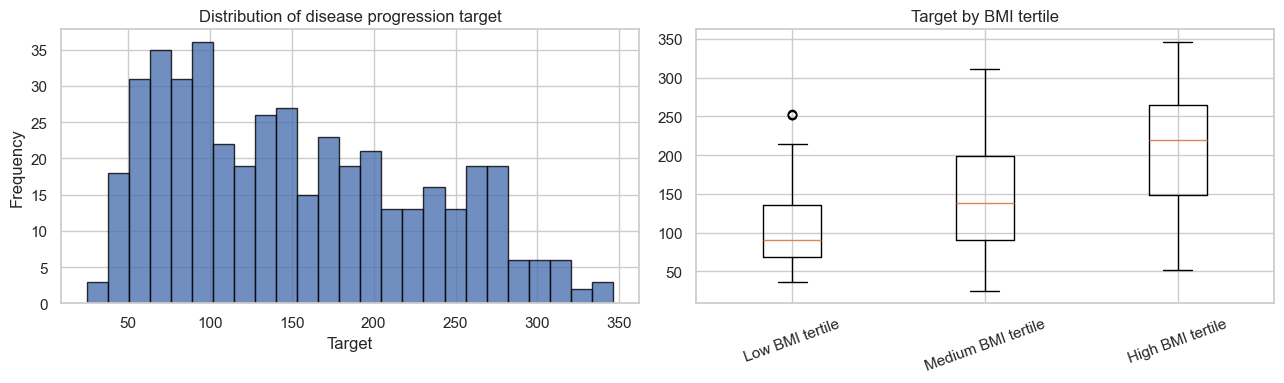

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(df["target"], bins=25, edgecolor="black", alpha=0.8)
axes[0].set_title("Distribution of disease progression target")
axes[0].set_xlabel("Target")
axes[0].set_ylabel("Frequency")

labels = ["Low BMI tertile", "Medium BMI tertile", "High BMI tertile"]
values = [df.loc[df["bmi_group"] == label, "target"].to_numpy() for label in labels]
axes[1].boxplot(values)
axes[1].set_xticks([1, 2, 3], labels=labels)
axes[1].set_title("Target by BMI tertile")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

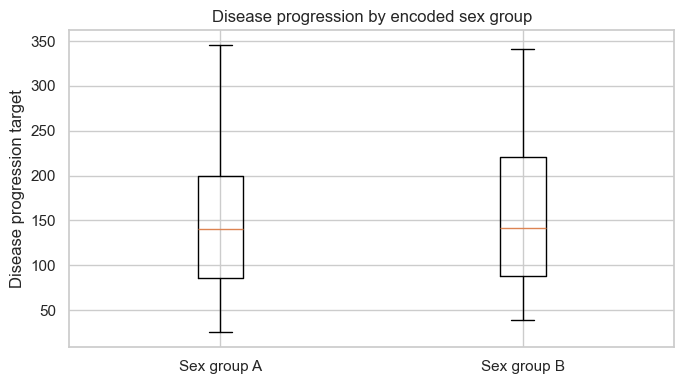

In [8]:
plt.figure(figsize=(7, 4))
sex_values_for_plot = [
    df.loc[df["sex_group"] == label, "target"].to_numpy()
    for label in ["Sex group A", "Sex group B"]
]
plt.boxplot(sex_values_for_plot)
plt.xticks([1, 2], ["Sex group A", "Sex group B"])
plt.title("Disease progression by encoded sex group")
plt.ylabel("Disease progression target")
plt.tight_layout()
plt.show()

## 6. Normality tests: Shapiro–Wilk and Kolmogorov–Smirnov

The Shapiro–Wilk test has null hypothesis that the sample comes from a normal distribution. For the Kolmogorov–Smirnov demonstration, the observed outcome is standardized and compared with a standard normal distribution.

**Caution:** The usual one-sample KS p-value assumes the reference distribution is specified independently. Here, mean and standard deviation are estimated from the same sample, so the KS p-value is not an exact calibrated normality test. Treat it as a demonstration and use plots plus Shapiro–Wilk as the main normality diagnostic. Normality of raw outcomes is not the only assumption relevant to t-tests/ANOVA; independence and variance behavior also matter.

In [9]:
normality_rows = []
for group_name, group in df.groupby("bmi_group", observed=True):
    values = group["target"].dropna().to_numpy()
    # Shapiro-Wilk
    shapiro_stat, shapiro_p = stats.shapiro(values)
    # KS comparison after standardizing using sample mean and SD (interpret cautiously)
    z = (values - values.mean()) / values.std(ddof=1)
    ks_stat, ks_p = stats.kstest(z, "norm")
    normality_rows.append({
        "group": str(group_name),
        "n": len(values),
        "shapiro_W": shapiro_stat,
        "shapiro_p": shapiro_p,
        "KS_D": ks_stat,
        "KS_p_caution": ks_p
    })

normality_results = pd.DataFrame(normality_rows)
normality_results

,group,n,shapiro_W,shapiro_p,KS_D,KS_p_caution
0,Low BMI tertile,155,0.9168,0.0000,0.1337,0.0071
1,Medium BMI tertile,140,0.9629,0.0008,0.0795,0.3220
2,High BMI tertile,147,0.9697,0.0025,0.0910,0.1647


In [10]:
for _, row in normality_results.iterrows():
    print(f"{row['group']}:")
    print(f"  Shapiro-Wilk p = {row['shapiro_p']:.4g} -> " +
          ("reject normality at alpha=0.05" if row["shapiro_p"] < ALPHA else "do not reject normality at alpha=0.05"))
    print(f"  KS p (caution) = {row['KS_p_caution']:.4g}")

Low BMI tertile:
  Shapiro-Wilk p = 8.949e-08 -> reject normality at alpha=0.05
  KS p (caution) = 0.00706
Medium BMI tertile:
  Shapiro-Wilk p = 0.0007672 -> reject normality at alpha=0.05
  KS p (caution) = 0.322
High BMI tertile:
  Shapiro-Wilk p = 0.002454 -> reject normality at alpha=0.05
  KS p (caution) = 0.1647


## 7. Two-sample parametric and non-parametric tests

We compare the outcome between the two encoded sex groups.

### Hypotheses
- **Null:** The two population means are equal for the t-test.
- **Alternative:** The two population means differ.
- The Mann–Whitney U test provides a non-parametric comparison of the group distributions.

We use Welch's t-test, which does not assume equal variances. A 95% confidence interval for the difference in means is calculated using the Welch–Satterthwaite degrees of freedom.

In [11]:
group_names = ["Sex group A", "Sex group B"]
x = df.loc[df["sex_group"] == group_names[0], "target"].dropna().to_numpy()
y = df.loc[df["sex_group"] == group_names[1], "target"].dropna().to_numpy()

t_stat, t_p = stats.ttest_ind(x, y, equal_var=False)
mw_stat, mw_p = stats.mannwhitneyu(x, y, alternative="two-sided")

mean_diff = x.mean() - y.mean()
var_x, var_y = x.var(ddof=1), y.var(ddof=1)
se_diff = np.sqrt(var_x / len(x) + var_y / len(y))
df_welch = (var_x / len(x) + var_y / len(y))**2 / (
    (var_x / len(x))**2 / (len(x) - 1) + (var_y / len(y))**2 / (len(y) - 1)
)
critical_t = stats.t.ppf(1 - ALPHA / 2, df_welch)
ci_low = mean_diff - critical_t * se_diff
ci_high = mean_diff + critical_t * se_diff

two_group_results = pd.DataFrame([
    {"test": "Welch two-sample t-test", "statistic": t_stat, "p_value": t_p},
    {"test": "Mann–Whitney U test", "statistic": mw_stat, "p_value": mw_p}
])
print("Group A n, mean, SD:", len(x), x.mean(), x.std(ddof=1))
print("Group B n, mean, SD:", len(y), y.mean(), y.std(ddof=1))
print(f"Mean difference (A - B): {mean_diff:.3f}")
print(f"95% CI for mean difference: [{ci_low:.3f}, {ci_high:.3f}]")
display(two_group_results)

Group A n, mean, SD: 235 149.0212765957447 75.90578093636822
Group B n, mean, SD: 207 155.66666666666666 78.45331306004283
Mean difference (A - B): -6.645
95% CI for mean difference: [-21.123, 7.832]


,test,statistic,p_value
0,Welch two-sample t-test,-0.9022,0.3674
1,Mann–Whitney U test,"23,270.0000",0.4324


In [12]:
for _, row in two_group_results.iterrows():
    decision = "statistically significant" if row["p_value"] < ALPHA else "not statistically significant"
    print(f"{row['test']}: p={row['p_value']:.5g}; result is {decision} at alpha={ALPHA}.")

Welch two-sample t-test: p=0.36744; result is not statistically significant at alpha=0.05.
Mann–Whitney U test: p=0.43243; result is not statistically significant at alpha=0.05.


## 8. One-way ANOVA across three BMI groups

### Hypotheses
- **Null:** The mean outcome is equal across the low, medium, and high BMI tertiles.
- **Alternative:** At least one group mean differs.

ANOVA tests whether any group mean differs overall. If the overall result is significant, Tukey HSD is used to examine pairwise differences while controlling family-wise error for those comparisons.

In [13]:
bmi_groups = [
    df.loc[df["bmi_group"] == label, "target"].dropna().to_numpy()
    for label in ["Low BMI tertile", "Medium BMI tertile", "High BMI tertile"]
]
anova_f, anova_p = stats.f_oneway(*bmi_groups)
print(f"One-way ANOVA: F = {anova_f:.4f}, p = {anova_p:.6g}")
print("Decision:", "Reject H0" if anova_p < ALPHA else "Do not reject H0")

One-way ANOVA: F = 95.3965, p = 3.95399e-35
Decision: Reject H0


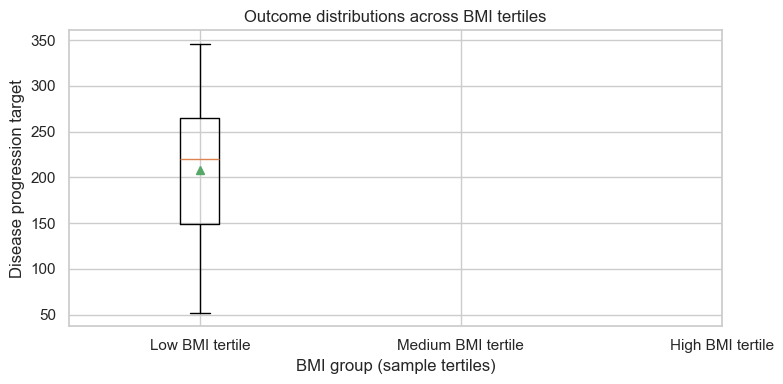

In [14]:
plt.figure(figsize=(8, 4))
plt.boxplot(values, showmeans=True)
plt.xticks([1, 2, 3], labels)
plt.title("Outcome distributions across BMI tertiles")
plt.xlabel("BMI group (sample tertiles)")
plt.ylabel("Disease progression target")
plt.tight_layout()
plt.show()

In [15]:
tukey = pairwise_tukeyhsd(
    endog=df["target"],
    groups=df["bmi_group"].astype(str),
    alpha=ALPHA
)
print(tukey)

             Multiple Comparison of Means - Tukey HSD, FWER=0.05             
     group1            group2        meandiff p-adj   lower    upper   reject
-----------------------------------------------------------------------------
High BMI tertile    Low BMI tertile -101.9214   0.0 -119.3875 -84.4554   True
High BMI tertile Medium BMI tertile  -62.6779   0.0  -80.5936 -44.7622   True
 Low BMI tertile Medium BMI tertile   39.2435   0.0   21.5548  56.9323   True
-----------------------------------------------------------------------------


## 9. Two-way ANOVA: BMI group, encoded sex group, and interaction

This model tests:
1. Whether mean outcome differs across BMI tertiles.
2. Whether mean outcome differs across encoded sex groups.
3. Whether the association between BMI tertile and outcome differs by encoded sex group (interaction).

The model uses Type II sums of squares. Interpret interaction results before drawing conclusions about main effects when the interaction is statistically significant.

In [16]:
two_way_model = smf.ols(
    "target ~ C(bmi_group) * C(sex_group)",
    data=df
).fit()

two_way_anova = sm.stats.anova_lm(two_way_model, typ=2)
two_way_anova

,sum_sq,df,F,PR(>F)
C(bmi_group),"792,039.1955",2.0000,95.2607,0.0000
C(sex_group),"2,876.2611",1.0000,0.6919,0.4060
C(bmi_group):C(sex_group),"11,561.2791",2.0000,1.3905,0.2501
Residual,"1,812,548.4190",436.0000,NaN,NaN


In [17]:
print(two_way_model.summary())

                            OLS Regression Results                            
Dep. Variable:                 target   R-squared:                       0.308
Model:                            OLS   Adj. R-squared:                  0.301
Method:                 Least Squares   F-statistic:                     38.89
Date:                Thu, 15 Oct 2026   Prob (F-statistic):           5.12e-33
Time:                        23:02:29   Log-Likelihood:                -2465.7
No. Observations:                 442   AIC:                             4943.
Df Residuals:                     436   BIC:                             4968.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                                                     coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------

## 10. Summarize findings automatically

The following summary reports the observed statistical decisions. Statistical significance does not measure practical importance, and results should be interpreted alongside effect sizes, confidence intervals, assumptions, and study limitations.

In [18]:
print("ADVANCED STATISTICAL ANALYSIS SUMMARY")
print("=" * 42)
print(f"Significance threshold: alpha = {ALPHA}")
print(f"Welch t-test: t={t_stat:.3f}, p={t_p:.5g}, mean difference A-B={mean_diff:.3f}")
print(f"95% CI for mean difference: [{ci_low:.3f}, {ci_high:.3f}]")
print(f"Mann–Whitney U: U={mw_stat:.3f}, p={mw_p:.5g}")
print(f"One-way ANOVA by BMI tertile: F={anova_f:.3f}, p={anova_p:.5g}")
print("\nTwo-way ANOVA table:")
display(two_way_anova)

ADVANCED STATISTICAL ANALYSIS SUMMARY
Significance threshold: alpha = 0.05
Welch t-test: t=-0.902, p=0.36744, mean difference A-B=-6.645
95% CI for mean difference: [-21.123, 7.832]
Mann–Whitney U: U=23270.000, p=0.43243
One-way ANOVA by BMI tertile: F=95.397, p=3.954e-35

Two-way ANOVA table:


,sum_sq,df,F,PR(>F)
C(bmi_group),"792,039.1955",2.0000,95.2607,0.0000
C(sex_group),"2,876.2611",1.0000,0.6919,0.4060
C(bmi_group):C(sex_group),"11,561.2791",2.0000,1.3905,0.2501
Residual,"1,812,548.4190",436.0000,NaN,NaN


## 11. Interpretation and limitations

Use the computed results below rather than relying on p-values alone.

- **Normality:** Shapiro–Wilk and the illustrative Kolmogorov–Smirnov results are reported for each BMI tertile. With moderate/large samples, normality tests can detect small departures from normality. The KS p-values here are only approximate because the mean and standard deviation were estimated from the same sample.
- **Two-group tests:** Welch's t-test compares group means without assuming equal variances. Mann–Whitney U compares ranks/distributions; it is not automatically a test of medians unless additional distributional assumptions hold. The mean difference and 95% confidence interval are included.
- **One-way ANOVA:** Tests equality of means across BMI tertiles. Tukey HSD provides family-wise-error-adjusted pairwise comparisons.
- **Two-way ANOVA:** Tests BMI tertile, encoded sex group, and their interaction. Interpret the interaction alongside the main effects.
- **Assumptions:** Observations are assumed independent. Normality tests do not prove or disprove model validity; inspect plots and consider variance heterogeneity. BMI tertiles are constructed from this sample.
- **Limitations:** The data are observational; BMI and sex features are standardized/encoded; results do not establish causation; grouping a continuous BMI feature loses information; and the dataset is modest in size.

## 12. Conclusion

The next cell generates a concise conclusion using the actual computed statistics. Do not interpret statistical significance as proof of practical importance or causality.

## 13. References

- Scikit-learn documentation, Diabetes dataset: https://scikit-learn.org/stable/datasets/toy_dataset.html#diabetes-dataset
- SciPy statistical functions: https://docs.scipy.org/doc/scipy/reference/stats.html
- Statsmodels ANOVA documentation: https://www.statsmodels.org/stable/anova.html
- Statsmodels multiple comparisons: https://www.statsmodels.org/stable/generated/statsmodels.stats.multicomp.pairwise_tukeyhsd.html


In [19]:
# Additional effect sizes, variance check, and an evidence-based conclusion.
from scipy.stats import levene

eta_squared = (
    sum(len(g) * (g.mean() - df["target"].mean())**2 for g in bmi_groups)
    / sum((df["target"] - df["target"].mean())**2)
)
levene_stat, levene_p = levene(*bmi_groups, center="median")

print("ADDITIONAL DIAGNOSTICS")
print(f"One-way ANOVA eta-squared: {eta_squared:.4f}")
print(f"Levene test across BMI groups: statistic={levene_stat:.4f}, p={levene_p:.5g}")
print("\nAUTOMATIC CONCLUSION")
print(
    f"At alpha={ALPHA}, Welch's t-test "
    f"{'rejects' if t_p < ALPHA else 'does not reject'} equal group means "
    f"(mean difference A-B={mean_diff:.2f}, 95% CI [{ci_low:.2f}, {ci_high:.2f}], p={t_p:.4g})."
)
print(
    f"The Mann–Whitney U test "
    f"{'detects' if mw_p < ALPHA else 'does not detect'} a statistically significant difference "
    f"between the encoded sex-group outcome distributions (p={mw_p:.4g})."
)
print(
    f"The one-way ANOVA across BMI tertiles "
    f"{'rejects' if anova_p < ALPHA else 'does not reject'} equal means "
    f"(F={anova_f:.2f}, p={anova_p:.4g}, eta-squared={eta_squared:.3f})."
)
for effect in ["C(bmi_group)", "C(sex_group)", "C(bmi_group):C(sex_group)"]:
    if effect in two_way_anova.index:
        pval = two_way_anova.loc[effect, "PR(>F)"]
        print(f"Two-way ANOVA {effect}: p={pval:.4g} -> " +
              ("statistically significant" if pval < ALPHA else "not statistically significant") + ".")
print(
    "Interpret findings as associations in this observational dataset. "
    "Normality and variance diagnostics should be considered alongside sample size, plots, "
    "and the independence assumption."
)


ADDITIONAL DIAGNOSTICS
One-way ANOVA eta-squared: 0.3029
Levene test across BMI groups: statistic=14.7070, p=6.5724e-07

AUTOMATIC CONCLUSION
At alpha=0.05, Welch's t-test does not reject equal group means (mean difference A-B=-6.65, 95% CI [-21.12, 7.83], p=0.3674).
The Mann–Whitney U test does not detect a statistically significant difference between the encoded sex-group outcome distributions (p=0.4324).
The one-way ANOVA across BMI tertiles rejects equal means (F=95.40, p=3.954e-35, eta-squared=0.303).
Two-way ANOVA C(bmi_group): p=4.743e-35 -> statistically significant.
Two-way ANOVA C(sex_group): p=0.406 -> not statistically significant.
Two-way ANOVA C(bmi_group):C(sex_group): p=0.2501 -> not statistically significant.
Interpret findings as associations in this observational dataset. Normality and variance diagnostics should be considered alongside sample size, plots, and the independence assumption.
